# Lab 03-2 Data visualization with matplotlib and seaborn

Nice visualization libraries:
- matplotlib: https://matplotlib.org/stable/index.html
- seaborn: http://seaborn.pydata.org/
- bokeh: https://docs.bokeh.org/en/latest/
- folium (geospatial visualization): https://python-visualization.github.io/folium/latest/
- kepler.gl (large-scale geospatial visualization): https://kepler.gl/

## Please submit your finished lab03 jupyter notebook via pull request in GitHub

In [1]:
# magic command to display matplotlib plots inline within the ipython notebook webpage
%matplotlib inline

# import necessary modules
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import matplotlib.cm as cm, matplotlib.font_manager as fm

## load the data sets

In [2]:
# load the gps coordinate data, using the date as the full set's index
# the data files are encoded as utf-8: specify so to prevent matplotlib from choking on diacritics
df = pd.read_csv('data/summer-travel-gps-full.csv', encoding='utf-8', index_col='date', parse_dates=True)
rs = pd.read_csv('data/summer-travel-gps-dbscan.csv', encoding='utf-8')

In [3]:
df.head()

,lat,lon,city,country
date,,,,
2014-05-14 09:07:00,51.481292,-0.451011,West Drayton,United Kingdom
2014-05-14 09:22:00,51.474005,-0.450999,Hounslow,United Kingdom
2014-05-14 10:51:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:24:00,51.478199,-0.446081,Hounslow,United Kingdom
2014-05-14 11:38:00,51.474146,-0.451562,Hounslow,United Kingdom


In [4]:
rs.head()

,lat,lon,date,city,country
0,51.478199,-0.446081,05/14/2014 10:51,Hounslow,United Kingdom
1,38.781775,-9.137544,05/14/2014 15:11,Lisbon,Portugal
2,38.771939,-9.128911,05/14/2014 15:41,Lisbon,Portugal
3,38.742987,-9.147780,05/14/2014 16:11,Lisbon,Portugal
4,38.693780,-9.206363,05/15/2014 14:19,Lisbon,Portugal


## First up: Bar Charts

<Axes: xlabel='country'>

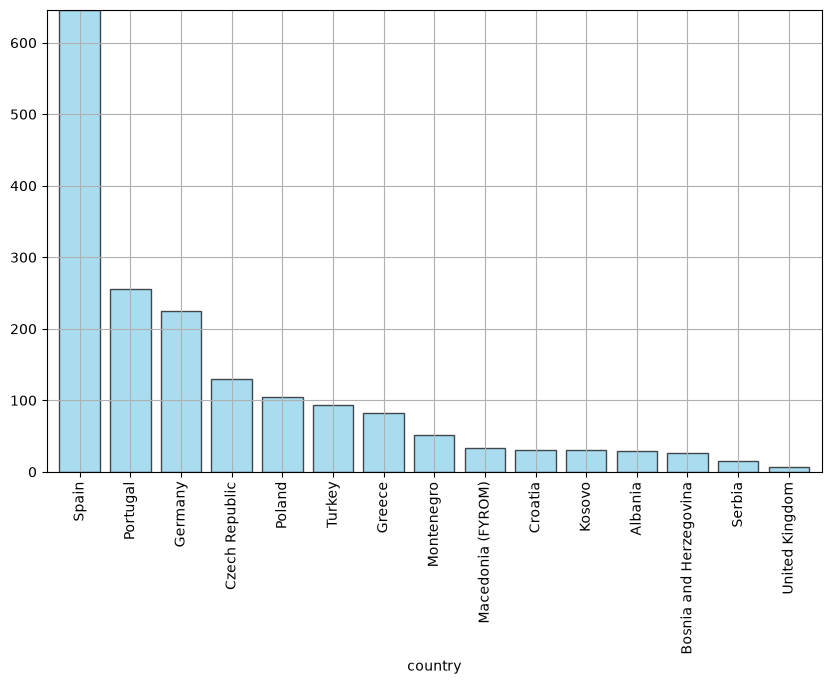

In [5]:
# Q1: Can you draw a bar chart for the most visited countries by using matplotlib and seaborn? You can use the df dataframe.
# Please style the chart to make it look nicer
# such as figsize, width, alpha, color, edgecolor, grid, xlim, and ylim
df["country"].value_counts().plot(kind='bar', figsize=(10, 6), width=0.8, alpha=0.7, color='skyblue', edgecolor='black', grid=True, xlim=(0, len(df["country"].value_counts())), ylim=(0, df["country"].value_counts().max()))

Now you try: re-create the plot above, but make the bars orange with maroon edges.

<Axes: xlabel='country'>

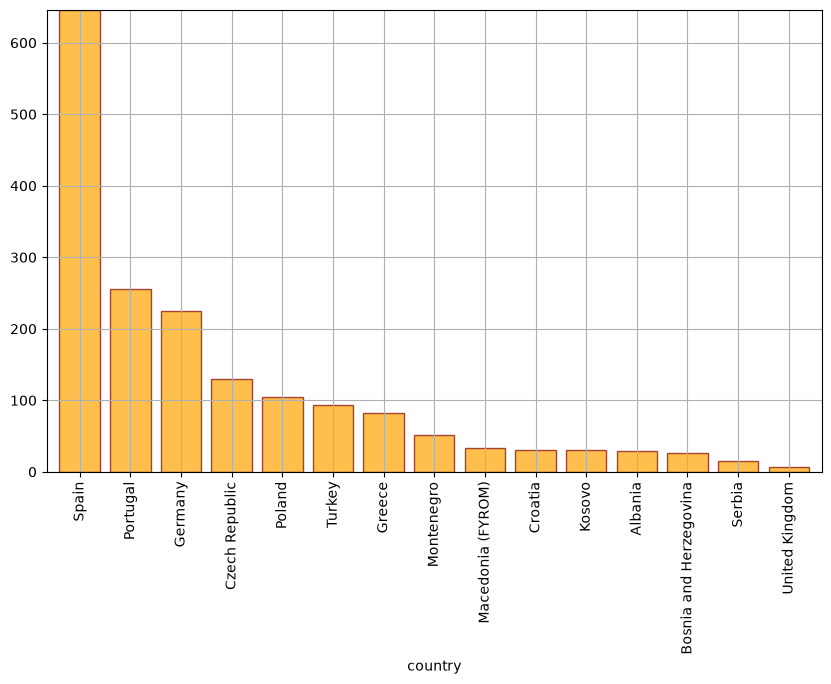

In [7]:
df["country"].value_counts().plot(kind='bar', figsize=(10, 6), width=0.8, alpha=0.7, color='orange', edgecolor='maroon', grid=True, xlim=(0, len(df["country"].value_counts())), ylim=(0, df["country"].value_counts().max()))

<Axes: xlabel='city'>

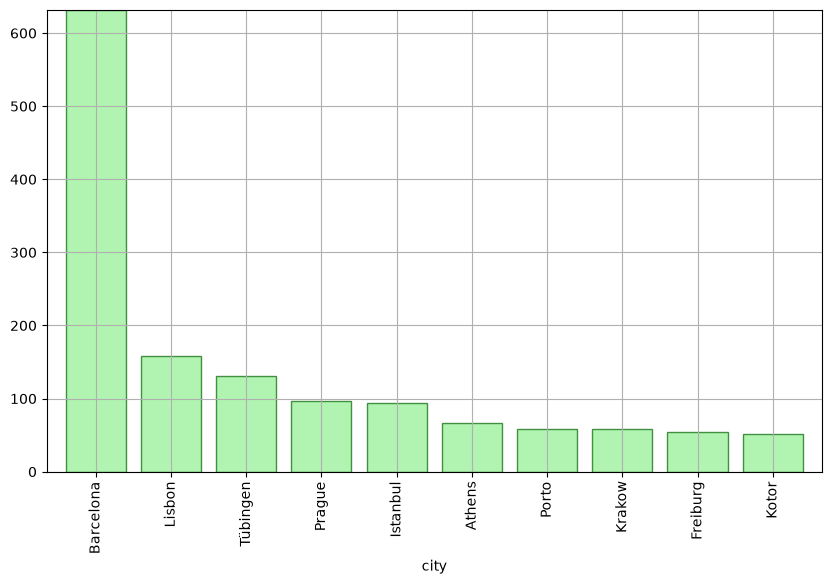

In [9]:
# Q2: Draw the same bar chart, but now for the most visited cities instead of countries
df["city"].value_counts().head(10).plot(kind='bar', figsize=(10, 6), width=0.8, alpha=0.7, color='lightgreen', edgecolor='darkgreen', grid=True, xlim=(0, len(df["city"].value_counts())), ylim=(0, df["city"].value_counts().max()))

## Next: scatter plots as simple maps

<Axes: xlabel='lon', ylabel='lat'>

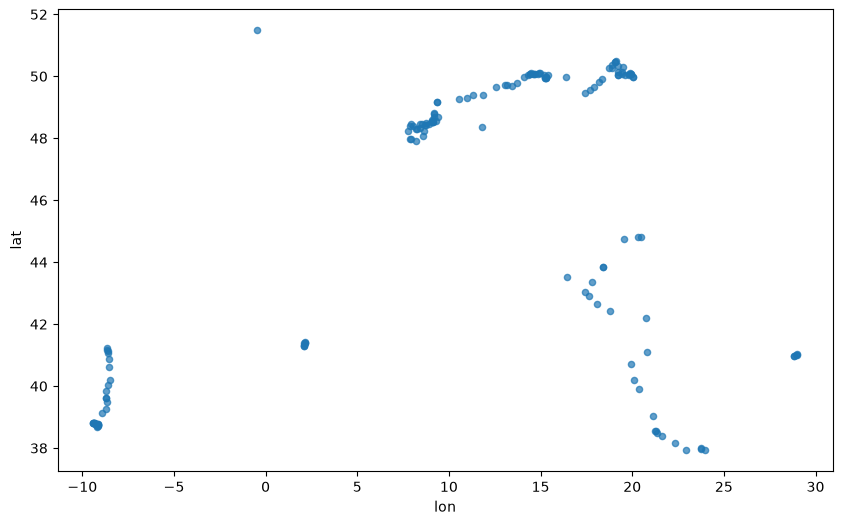

In [12]:
# Q3: Draw a scatter plot the longitude and latitude data, with matplotlib and seaborn defaults. 
# You can use the rs dataframe.
# Please style the chart to make it look nicer with good size and alpha settings. 
rs.plot(kind='scatter', x='lon', y='lat', figsize=(10, 6), alpha=0.7, s=20)

<Axes: xlabel='lon', ylabel='lat'>

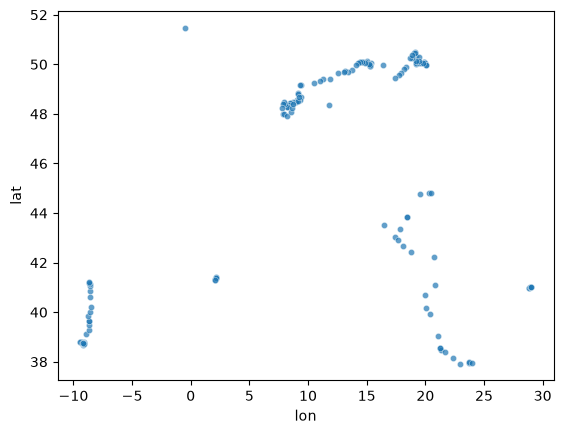

In [14]:
import seaborn as sns
sns.scatterplot(data=rs, x='lon', y='lat', alpha=0.7, s=20)

## Line charts, with annotation

In [18]:
# get the count of records by date
countdata = df.groupby(df.index.date).size()
countdata.head()

2014-05-14    36
2014-05-15    61
2014-05-16    57
2014-05-17    64
2014-05-18    50
dtype: int64

<Axes: >

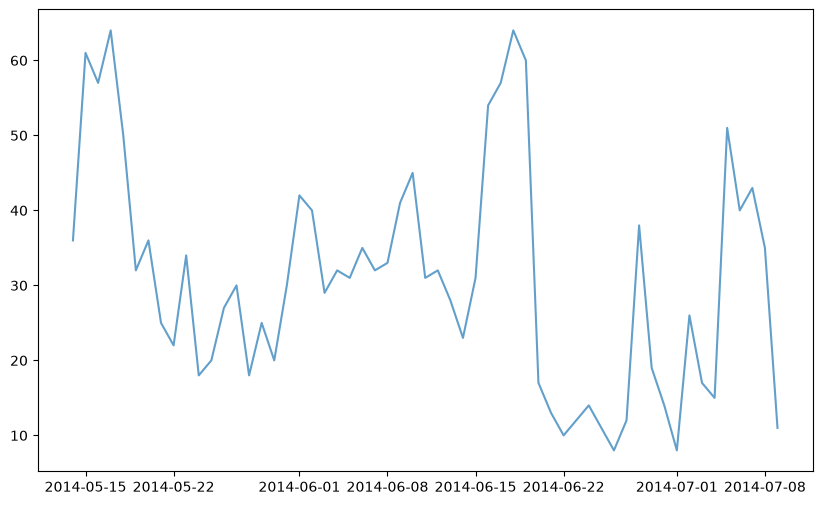

In [19]:
# Q4: Draw a  matplotlib and seaborn line chart from countdata. 
# Please style the chart to make it look nicer with good size and alpha settings. 
countdata.plot(kind='line', figsize=(10, 6), alpha=0.7)

Text(2014-05-17, 114, 'Peak')

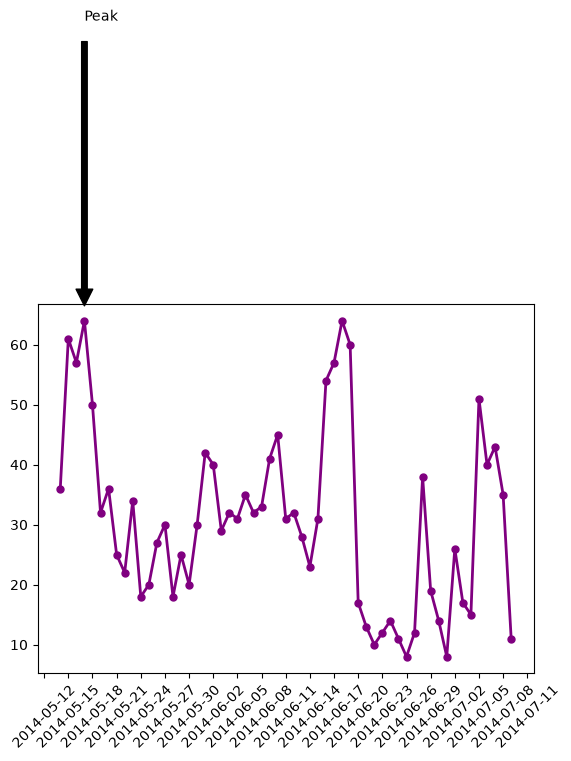

In [23]:
# Q5: Now you try: re-create the plot above with different line widths, colors, and point markers. 
# Play with moving the annotation labels around. Make the vertical tick marks 3 days apart instead of 5.
# experiment with a more advanced challenge like smoothing the line:
# - https://stackoverflow.com/questions/5283649/plot-smooth-line-with-pyplot
# - https://stackoverflow.com/questions/25825946/generating-smooth-line-graph-using-matplotlib
plt.plot(countdata.index, countdata.values, color='purple', linewidth=2, marker='o', markersize=5)
import matplotlib.dates as mdates
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.xticks(rotation=45)
plt.annotate('Peak', xy=(countdata.idxmax(), countdata.max()), xytext=(countdata.idxmax(), countdata.max()+50),
             arrowprops=dict(facecolor='black', shrink=0.05))

## Pie charts

In [12]:
cities = df['city'].value_counts()
print(cities.count())
cities.head()

113


city
Barcelona    632
Lisbon       158
Tübingen     131
Prague        97
Istanbul      94
Name: count, dtype: int64

<Axes: >

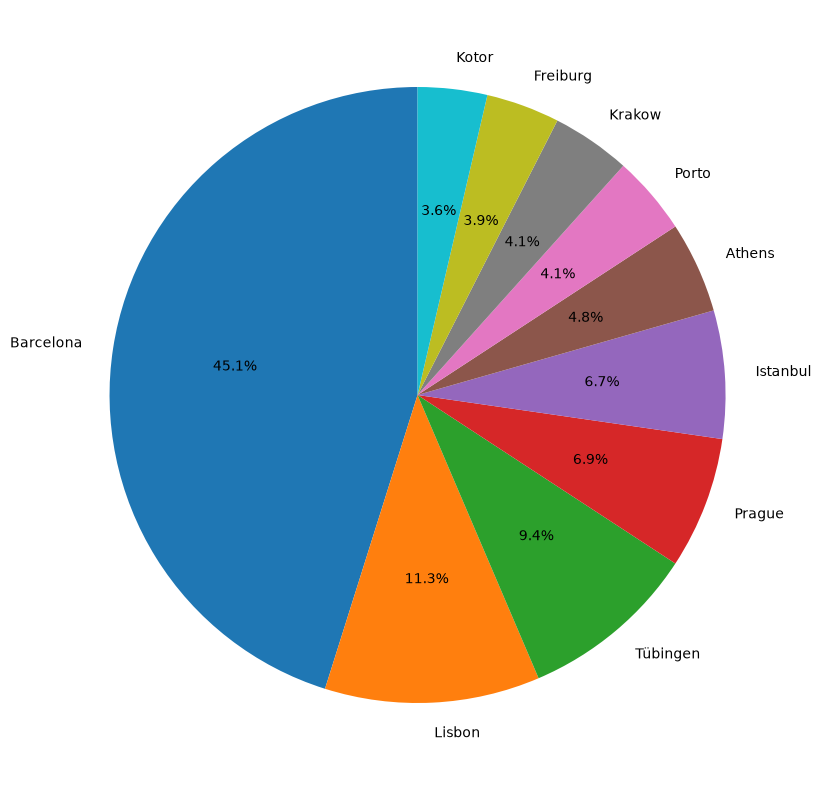

In [24]:
# Q6: draw a pie chart for cities.
# Please style the chart to make it look nicer. 
df["city"].value_counts().head(10).plot(kind='pie', figsize=(10, 10), autopct='%1.1f%%', startangle=90)

## Extra task: Kepler.gl
Some examples: https://docs.kepler.gl/docs/keplergl-jupyter and https://jamesopacich.medium.com/display-a-kepler-gl-map-69d807dae082

In [29]:
# Q7: can you visualize the GPS points by using Kepler.gl? 
from keplergl import KeplerGl
KeplerGl(height=600, data={"GPS Points": df}) .save_to_html(file_name="kepler_map.html", read_only=True)

Map saved to kepler_map.html!


In [26]:
%pip install keplergl

  Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 49.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.3/624.3 kB 34.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 68.6 MB/s  0:00:00
Using cached pyogrio-0.13.0-cp311-abi3-macosx_12_0_arm64.whl (24.7 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 77.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 77.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [keplergl]/11 [geopandas]
Note: you may need to restart the kernel to use updated packages.
